# HW4-1 CIFAR-10 CNN

使用 CIFAR-10 資料集建立 CNN 模型，辨識 10 種圖片類別。

## 1. 匯入套件

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from ipywidgets import interact_manual, IntSlider

np.random.seed(42)
tf.random.set_seed(42)

## 2. 讀取 CIFAR-10 資料

圖片大小是 32 × 32，包含 RGB 三個色彩通道。

In [19]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("訓練圖片：", x_train.shape)
print("訓練標籤：", y_train.shape)
print("測試圖片：", x_test.shape)
print("測試標籤：", y_test.shape)

訓練圖片： (50000, 32, 32, 3)
訓練標籤： (50000, 1)
測試圖片： (10000, 32, 32, 3)
測試標籤： (10000, 1)


## 3. 訓練圖片

顯示訓練圖片與正確的類別名稱。

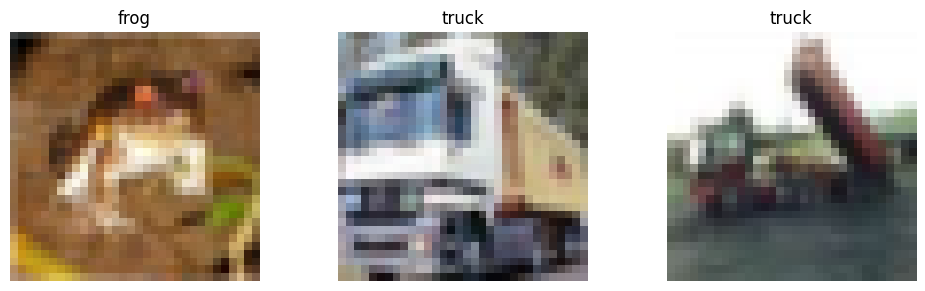

In [20]:
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. 資料預處理

圖片除以 255 進行正規化，標籤使用 one-hot encoding。

In [21]:
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

y_train_onehot = to_categorical(y_train.reshape(-1), 10)
y_test_onehot = to_categorical(y_test.reshape(-1), 10)

print("x_train_norm：", x_train_norm.shape)
print("x_test_norm：", x_test_norm.shape)
print("y_train_onehot：", y_train_onehot.shape)
print("y_test_onehot：", y_test_onehot.shape)

x_train_norm： (50000, 32, 32, 3)
x_test_norm： (10000, 32, 32, 3)
y_train_onehot： (50000, 10)
y_test_onehot： (10000, 10)


## 5. 建立 CNN 模型

使用兩層卷積、兩層池化，再接全連接層進行分類。

In [22]:
model = Sequential([
    Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

## 6. 各層 shape 與參數量

批次大小為 128，輸入為 `(128, 32, 32, 3)`。

卷積層參數：`(濾鏡高 × 濾鏡寬 × 輸入通道數 + 1) × 濾鏡數量`。

全連接層參數：`(輸入數量 + 1) × 神經元數量`。池化層與 Flatten 沒有訓練參數。

In [23]:
batch_size = 128
print("批次 input shape：", (batch_size, 32, 32, 3))

for layer in model.layers:
    shape = tuple(batch_size if d is None else int(d) for d in layer.output.shape)
    print(layer.name, "output shape:", shape, "params:", layer.count_params())

print("模型總參數：", model.count_params())

批次 input shape： (128, 32, 32, 3)
conv2d_2 output shape: (128, 32, 32, 32) params: 896
max_pooling2d_2 output shape: (128, 16, 16, 32) params: 0
conv2d_3 output shape: (128, 16, 16, 64) params: 18496
max_pooling2d_3 output shape: (128, 8, 8, 64) params: 0
flatten_1 output shape: (128, 4096) params: 0
dense_2 output shape: (128, 128) params: 524416
dense_3 output shape: (128, 10) params: 1290
模型總參數： 545098


### 參數數量計算

In [24]:
print("Conv2D(32): (3×3×3+1)×32 =", (3*3*3+1)*32)
print("Conv2D(64): (3×3×32+1)×64 =", (3*3*32+1)*64)
print("Dense(128): (8×8×64+1)×128 =", (8*8*64+1)*128)
print("Dense(10): (128+1)×10 =", (128+1)*10)

Conv2D(32): (3×3×3+1)×32 = 896
Conv2D(64): (3×3×32+1)×64 = 18496
Dense(128): (8×8×64+1)×128 = 524416
Dense(10): (128+1)×10 = 1290


## 7. 編譯與訓練

`categorical_crossentropy`、`adam`，訓練 20 個 epochs，每批 128 筆；訓練資料的 20% 作為驗證資料。

In [25]:
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

history = model.fit(
    x_train_norm,
    y_train_onehot,
    validation_split=0.2,
    epochs=20,
    batch_size=128,
    verbose=1
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 251ms/step - accuracy: 0.4335 - loss: 1.5799 - val_accuracy: 0.5565 - val_loss: 1.2921
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 73s 225ms/step - accuracy: 0.5790 - loss: 1.1920 - val_accuracy: 0.6022 - val_loss: 1.1382
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 237ms/step - accuracy: 0.6363 - loss: 1.0379 - val_accuracy: 0.6270 - val_loss: 1.0698
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 72s 230ms/step - accuracy: 0.6712 - loss: 0.9379 - val_accuracy: 0.6487 - val_loss: 1.0127
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 223ms/step - accuracy: 0.6992 - loss: 0.8616 - val_accuracy: 0.6680 - val_loss: 0.9649
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 236ms/step - accuracy: 0.7229 - loss: 0.7958 - val_accuracy: 0.6797 - val_loss: 0.9407
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 74s 236ms/step - accuracy: 0.7416 - loss: 0.7409 - val_accuracy: 0.6848 - val_loss: 0.9291
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 225ms/step - accuracy: 0.7595 - loss: 0

## 8. Accuracy 與 Loss

比較訓練資料和驗證資料的變化，觀察是否有 overfitting。

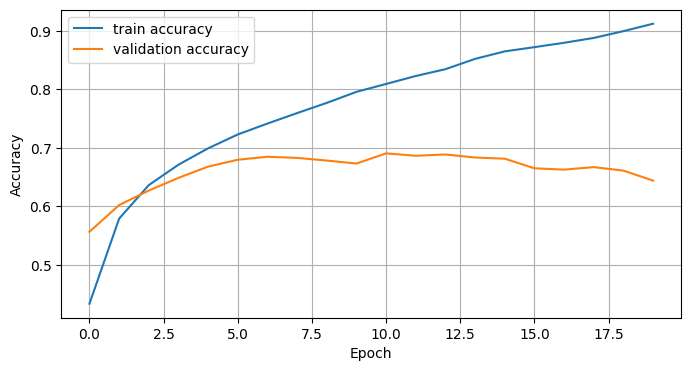

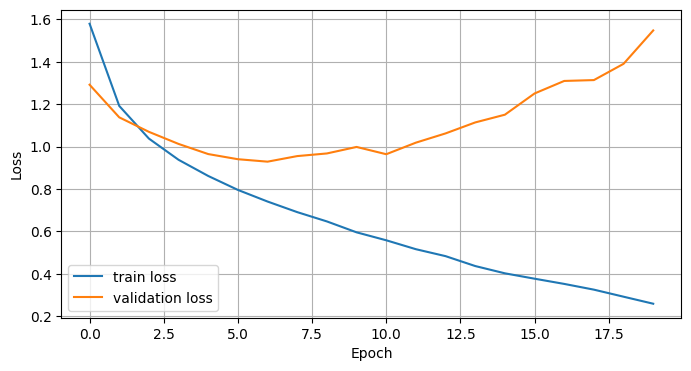

In [26]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

### Overfitting 觀察

In [27]:
best_epoch = int(np.argmax(history.history["val_accuracy"])) + 1
print("最高 validation accuracy：", round(max(history.history["val_accuracy"]), 4))
print("出現在第", best_epoch, "個 epoch")
print("最後 train accuracy：", round(history.history["accuracy"][-1], 4))
print("最後 validation accuracy：", round(history.history["val_accuracy"][-1], 4))

if history.history["loss"][-1] < history.history["loss"][best_epoch - 1] and history.history["val_loss"][-1] > history.history["val_loss"][best_epoch - 1]:
    print("後期 train loss 下降、validation loss 上升，可能有 overfitting。")
else:
    print("可對照上面的 loss 與 accuracy 曲線觀察 overfitting。")

最高 validation accuracy： 0.6906
出現在第 11 個 epoch
最後 train accuracy： 0.9123
最後 validation accuracy： 0.644
後期 train loss 下降、validation loss 上升，可能有 overfitting。


## 9. 測試資料評估

以全部 10000 筆測試資料評估。

In [28]:
test_loss, test_accuracy = model.evaluate(x_test_norm, y_test_onehot, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)

Test loss: 1.569158911705017
Test accuracy: 0.6396999955177307
Test accuracy (%): 63.96999955177307


## 10. 測試資料預測

對全部測試資料預測，並顯示預測與正確的類別名稱。

79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step
測試 input shape: (10000, 32, 32, 3)
預測 output shape: (10000, 10)


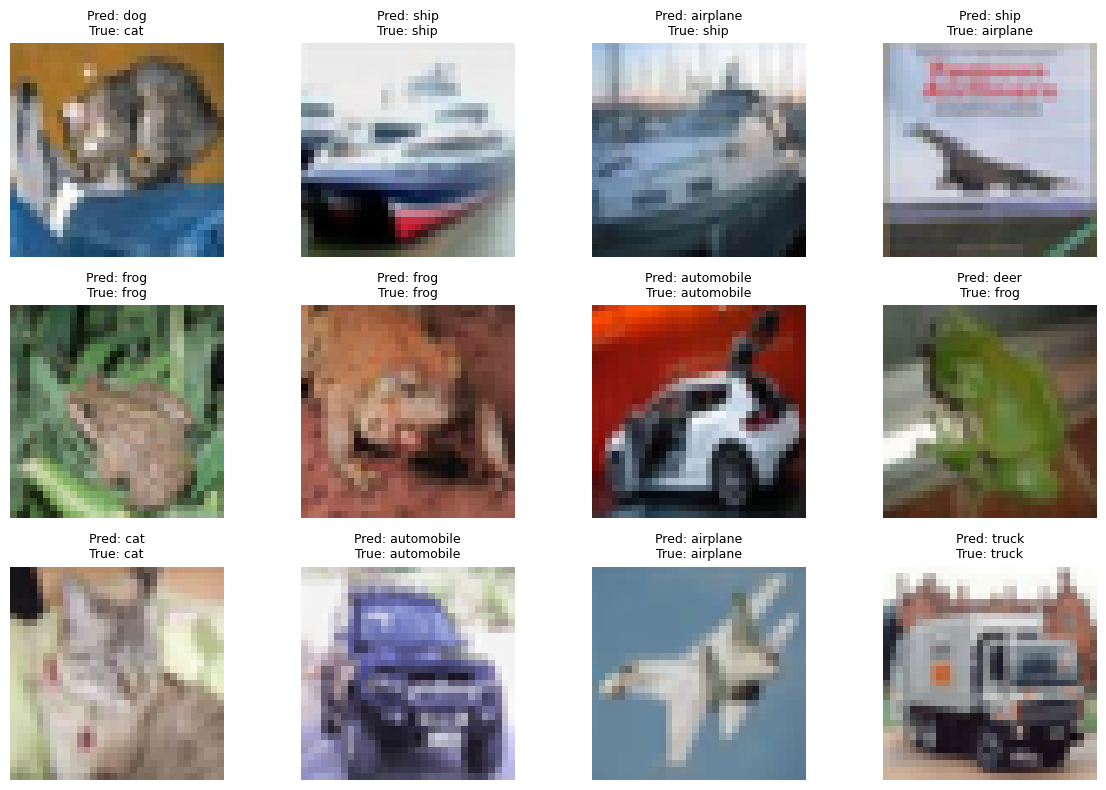

In [29]:
prediction = model.predict(x_test_norm, batch_size=128)
predicted_labels = np.argmax(prediction, axis=1)
true_labels = y_test.reshape(-1)

print("測試 input shape:", x_test_norm.shape)
print("預測 output shape:", prediction.shape)

plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        "Pred: " + class_names[predicted_labels[i]] + "\nTrue: " + class_names[true_labels[i]],
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Confusion Matrix

[[653  17 104  16   4  10   4  42 121  29]
 [ 28 786  12  12   0  12   0  27  49  74]
 [ 48   3 621  43  40  55  21 125  36   8]
 [ 24  21 120 372  46 214  23 134  33  13]
 [ 35   8 131  58 440  47  22 235  22   2]
 [ 15   6  79 105  20 570   6 179  18   2]
 [ 21  15 102  85  62  62 587  39  18   9]
 [ 15   2  30  17  10  29   3 887   3   4]
 [ 41  27  22   7   2   9   1  23 854  14]
 [ 61 133  19   7   2  12   3  73  63 627]]


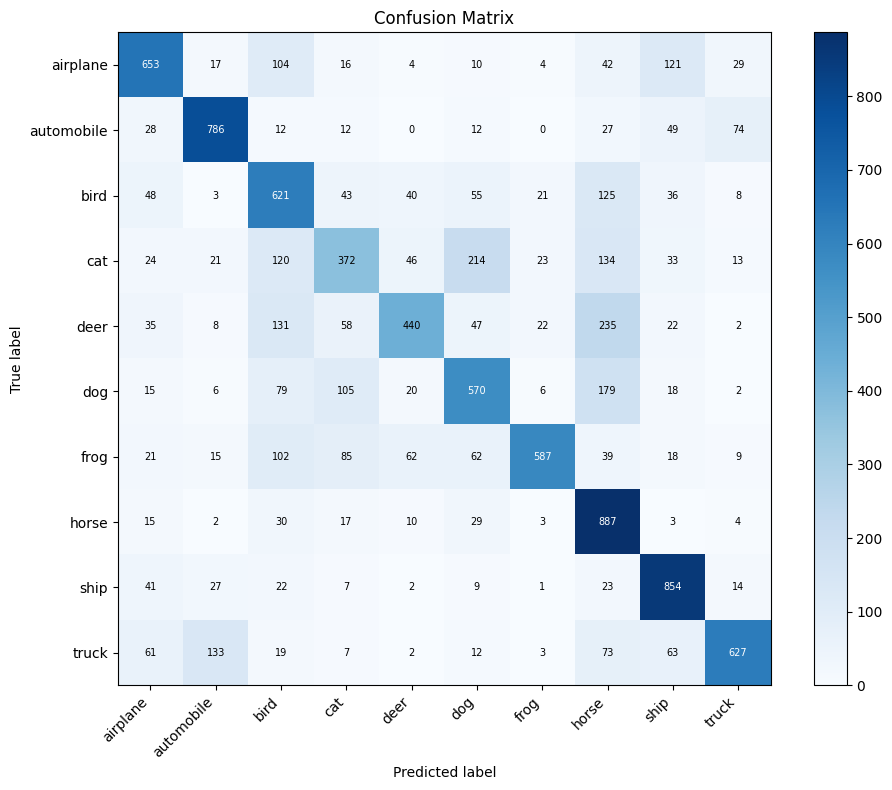

In [30]:
cm = tf.math.confusion_matrix(true_labels, predicted_labels, num_classes=10).numpy()
print(cm)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

## 12. 儲存完整模型

模型以 `.keras` 格式儲存。

In [31]:
model.save("cifar10_cnn_hw4_1.keras")
print("模型已儲存：cifar10_cnn_hw4_1.keras")

模型已儲存：cifar10_cnn_hw4_1.keras


## 13. interact_manual 預測

輸入測試圖片的編號，按下按鈕查看預測結果。

In [32]:
def show_prediction(index):
    plt.figure(figsize=(4, 4))
    plt.imshow(x_test[index])
    plt.axis("off")
    plt.title("Pred: " + class_names[predicted_labels[index]] +
              "\nTrue: " + class_names[true_labels[index]])
    plt.show()
    print("預測信心度：", round(float(np.max(prediction[index])) * 100, 2), "%")

interact_manual(show_prediction, index=IntSlider(value=0, min=0, max=9999, step=1, description="圖片編號"))

interactive(children=(IntSlider(value=0, description='圖片編號', max=9999), Button(description='Run Interact', sty…

<function __main__.show_prediction(index)>

## 14. 結果

使用 CNN 對 CIFAR-10 的 10 類圖片進行分類，透過訓練曲線、測試準確率與混淆矩陣查看模型表現。